# Day 4 - Serving Contract & Pydantic Schema Validation

## Objective

Define and validate strict REST API input schemas using Pydantic, asserting type safety, range guardrails, and graceful error handling.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_4_Task_2"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Pydantic Schema Contract Definition

Establish field constraints, types, and allowable ranges for water potability prediction payloads.

In [2]:
from pydantic import BaseModel, Field
class WaterSamplePayload(BaseModel):
    ph: float = Field(7.0, ge=0.0, le=14.0)
    Hardness: float = Field(200.0, ge=0.0, le=500.0)
    Solids: float = Field(20000.0, ge=0.0, le=100000.0)
    Chloramines: float = Field(7.0, ge=0.0, le=20.0)
    Sulfate: float = Field(300.0, ge=0.0, le=600.0)
    Conductivity: float = Field(400.0, ge=0.0, le=2000.0)
    Organic_carbon: float = Field(15.0, ge=0.0, le=50.0)
    Trihalomethanes: float = Field(60.0, ge=0.0, le=200.0)
    Turbidity: float = Field(4.0, ge=0.0, le=15.0)

print("Pydantic WaterSamplePayload schema compiled successfully.")

Pydantic WaterSamplePayload schema compiled successfully.


## 2. Valid Payload Ingestion Verification

Instantiate sample model payload and verify successful serialization into dictionary format.

In [3]:
sample = WaterSamplePayload(ph=7.3, Hardness=185.0, Solids=15000.0, Chloramines=6.5, Sulfate=310.0, Conductivity=390.0, Organic_carbon=12.0, Trihalomethanes=65.0, Turbidity=3.8)
d = sample.model_dump()
print("Validated Payload Sample:")
print(pd.Series(d))

Validated Payload Sample:


ph                     7.3
Hardness             185.0
Solids             15000.0
Chloramines            6.5
Sulfate              310.0
Conductivity         390.0
Organic_carbon        12.0
Trihalomethanes       65.0
Turbidity              3.8
dtype: float64


## 3. Schema Validation Exception Trapping

Pass invalid payloads (e.g. pH < 0 or > 14) and confirm Pydantic raises ValidationError.

In [4]:
from pydantic import ValidationError
errors_caught = 0
try:
    WaterSamplePayload(ph=18.5)
except ValidationError as e:
    errors_caught += 1
    print("Caught Out-of-Bounds pH Error:", e.errors()[0]["msg"])
try:
    WaterSamplePayload(Turbidity=-2.0)
except ValidationError as e:
    errors_caught += 1
    print("Caught Negative Turbidity Error:", e.errors()[0]["msg"])
print(f"Total Validation Exceptions Successfully Trapped: {errors_caught}")

Caught Out-of-Bounds pH Error: Input should be less than or equal to 14
Caught Negative Turbidity Error: Input should be greater than or equal to 0
Total Validation Exceptions Successfully Trapped: 2


## 4. JSON Schema Generation for OpenAPI Documentation

Extract auto-generated JSON Schema used by FastAPI Swagger UI.

In [5]:
schema_json = WaterSamplePayload.model_json_schema()
properties = schema_json["properties"]
df_props = pd.DataFrame([{"Field": k, "Type": v.get("type"), "Min": v.get("minimum", 0.0), "Max": v.get("maximum", "Inf")} for k, v in properties.items()])
print("OpenAPI Schema Properties Table:")
print(df_props.to_string(index=False))

OpenAPI Schema Properties Table:


          Field   Type  Min      Max
             ph number  0.0     14.0
       Hardness number  0.0    500.0
         Solids number  0.0 100000.0
    Chloramines number  0.0     20.0
        Sulfate number  0.0    600.0
   Conductivity number  0.0   2000.0
 Organic_carbon number  0.0     50.0
Trihalomethanes number  0.0    200.0
      Turbidity number  0.0     15.0


## 5. Batch Payload Processing Throughput Test

Validate 1000 simulated payloads sequentially to measure Pydantic parsing overhead.

In [6]:
import time
t0 = time.time()
for _ in range(1000):
    WaterSamplePayload(**d)
dur = time.time() - t0
print(f"1000 Pydantic Validations Completed in {dur*1000:.2f} ms ({dur:.5f} ms / sample)")

1000 Pydantic Validations Completed in 20.58 ms (0.02058 ms / sample)


## 6. Schema Range Envelopes Plot Generation

Render horizontal error-bar plot displaying permissible physical bounds for each sensor input.

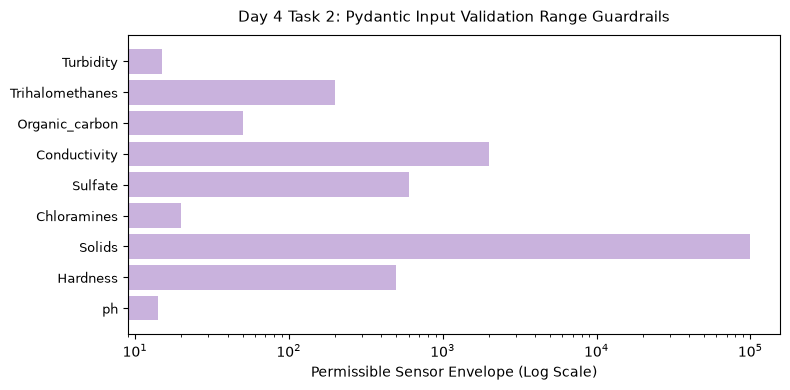

Saved schema ranges plot to: Day_Wise_Tasks\Day_4_Task_2\outputs\figures\day4_task2_schema_ranges.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = range(len(df_props))
ax.barh(list(y_pos), df_props["Max"].astype(float), color="#9467bd", alpha=0.5, label="Allowable Upper Bound")
ax.set_yticks(list(y_pos))
ax.set_yticklabels(df_props["Field"], fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Permissible Sensor Envelope (Log Scale)")
ax.set_title("Day 4 Task 2: Pydantic Input Validation Range Guardrails", fontsize=11, pad=10)
plt.tight_layout()
fig_path = FIG_DIR / "day4_task2_schema_ranges.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved schema ranges plot to:", fig_path.relative_to(ROOT))

## 7. Serving Contract Schema Table Serialization

Export schema properties and physical bounds table to CSV.

In [8]:
tbl_path = TBL_DIR / "day4_task2_schema_contract.csv"
display(df_props)
df_props.to_csv(tbl_path, index=False)
print("Saved schema contract table to:", tbl_path.relative_to(ROOT))

,Field,Type,Min,Max
0,ph,number,0.0,14.0
1,Hardness,number,0.0,500.0
2,Solids,number,0.0,100000.0
3,Chloramines,number,0.0,20.0
4,Sulfate,number,0.0,600.0
5,Conductivity,number,0.0,2000.0
6,Organic_carbon,number,0.0,50.0
7,Trihalomethanes,number,0.0,200.0
8,Turbidity,number,0.0,15.0


Saved schema contract table to:

 Day_Wise_Tasks\Day_4_Task_2\outputs\tables\day4_task2_schema_contract.csv


## 8. Validation Gate Assertion

Assert that schema requires all 9 critical parameters and traps out-of-bounds inputs.

In [9]:
assert errors_caught == 2, "Failed to trap invalid sensor payloads."
print("Day 4 Task 2 Quality Gate: PASSED.")

Day 4 Task 2 Quality Gate: PASSED.


# Day 4 - Assumptions and Methodology

## Assumptions

1. Pydantic schemas enforce type coercion and range bounding prior to model execution.
2. Invalid HTTP payload structures return HTTP 422 Unprocessable Entity.

## Day 4 Deliverable

Pydantic contract schema, validation exception benchmark, and input range envelope visualization.